# WPBC: predictor subsets

Thirty-two measurements are taken from a tumour biopsy. The goal is to identify
which of them predict recurrence, with the expected output being a list of
features to report or to build into an assay.

With correlated measurements, several subsets can give similar predictions.
This study compares the subset from one fit with resampling frequencies,
removal tests and alternative subsets.

The problem differs from the one in [](after_selection.ipynb), where the
findings are absent altogether. Here the predictive signal is present; the
difficulty is that many different subsets carry it about equally well.

The study separates four questions about correlated predictors: what one path
selected, how often a term returns, whether it is necessary for prediction, and whether
it survives error-controlled selection.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | which tumour measurements predict recurrence, to report or build into an assay |
| **Observed response** | `recurred`, binary |
| **Estimand** | the set of features with non-zero effect — a selection problem, not an effect size |
| **Units** | the 32 morphological features are on their own measurement scales; the label is unitless |
| **Sampling unit** | one patient |
| **Dependence** | treated as independent |
| **Split / resampling unit** | the patient; stability selection resamples patients |
| **Tuning** | `mstop` by cross-validated risk |
| **Uncertainty** | selection frequencies with a per-family error bound, plus bootstrap refits |
| **Claim type** | predictive and selection-oriented. The study's finding is that many different feature sets fit equally well |
:::


## The data

`wpbc`, the Wisconsin Prognostic Breast Cancer data. The 32 predictors are
measurements from a digitised image of a biopsy: ten quantities each recorded
three ways, as a mean, a standard error and a "worst" value, plus tumour size
and lymph-node count. Several of the quantities are geometrically related.

[](wpbc_censoring.ipynb) covers the limitations of the binary recurrence label
used here. This study concerns selection, so a classifier is the appropriate
vehicle and those limitations are inherited rather than examined.

The cells below keep the complete cases and summarise the correlations among
the predictors.


In [1]:
import numpy as np
import polars as pl

import mboostrs as mb

raw = mb.datasets.wpbc(output="records")
complete = np.ones(len(raw["time"]), dtype=bool)
for column in raw:
    complete &= np.isfinite(np.asarray(raw[column], dtype=float))
data = {k: np.asarray(v)[complete] for k, v in raw.items()}
n = len(data["time"])
predictors = [c for c in data if c not in ("time", "status")]
modelling = {**data, "recurred": np.asarray(data["status"], dtype=float)}
formula = "recurred ~ " + " + ".join(predictors)

matrix = np.column_stack([data[c] for c in predictors])
correlations = np.corrcoef(matrix.T)
upper = np.triu_indices(len(predictors), 1)
print(f"n = {n}, predictors = {len(predictors)}, "
      f"events = {int(data['status'].sum())}")
print(f"pairwise |correlation|: median {np.median(np.abs(correlations[upper])):.2f}, "
      f"max {np.abs(correlations[upper]).max():.3f}")
print(f"pairs correlated above 0.9: {int((np.abs(correlations[upper]) > 0.9).sum())}")

n = 194, predictors = 32, events = 46
pairwise |correlation|: median 0.21, max 0.996
pairs correlated above 0.9: 17


Pairwise absolute correlation among the predictors has a median of 0.21 and a
maximum of 0.996, with 17 pairs above 0.9. The three size measurements of a
single tumour — mean radius, mean perimeter and mean area — correlate at 0.99
or higher. Their near-redundancy makes it difficult to attribute predictive information
to one measurement rather than another.


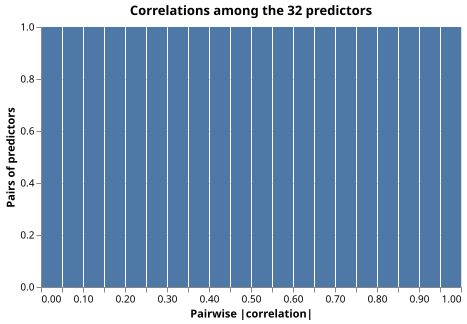

In [2]:
import altair as alt

corr_frame = pl.DataFrame({"abs_corr": np.abs(correlations[upper])})
alt.Chart(corr_frame).mark_bar(color="#4e79a7").encode(
    x=alt.X("abs_corr:Q", title="Pairwise |correlation|",
            bin=alt.Bin(maxbins=24)),
    y=alt.Y("count()", title="Pairs of predictors"),
    tooltip=[alt.Tooltip("abs_corr:Q", title="|correlation|"),
             alt.Tooltip("count()", title="Pairs")],
).properties(title="Correlations among the 32 predictors", width=420, height=260)

## Initial fit

Fitting the classifier and reporting the terms that received a coefficient is
the analysis as usually run.


In [3]:
fit = mb.glmboost(formula, data=modelling, family=mb.Binomial(),
                  control=mb.boost_control(300, 0.1))
selected = [k for k in fit.coef() if k not in ("(Intercept)", "(offset)")]
print(f"{len(selected)} of {len(predictors)} predictors received a coefficient")
print(f"first six: {selected[:6]}")

17 of 32 predictors received a coefficient
first six: ['mean_texture', 'mean_smoothness', 'mean_symmetry', 'mean_fractaldim', 'SE_texture', 'SE_perimeter']


Seventeen of the 32 predictors received a coefficient. Reported as "17
morphological features associated with recurrence", all seventeen carry the
same apparent status.

Three checks examine that claim from different directions: how often each
predictor is chosen under resampling, whether the most-chosen predictor can be
dropped, and whether a different subset predicts as well.


## Extension: bootstrap selection frequencies

The first check refits on bootstrap samples. Each replicate draws n rows with
replacement and refits the classifier; a predictor's selection frequency is the
proportion of replicates in which it received a coefficient. Eighty replicates
are sufficient for the pattern to stabilise.


predictor,selected in,percent
str,str,i64
"""pnodes""","""78/80""",98
"""worst_smoothness""","""75/80""",94
"""mean_fractaldim""","""63/80""",79
"""tsize""","""63/80""",79
"""SE_concavepoints""","""62/80""",78
"""mean_texture""","""60/80""",75
"""SE_perimeter""","""58/80""",72
"""mean_symmetry""","""57/80""",71
"""SE_texture""","""56/80""",70


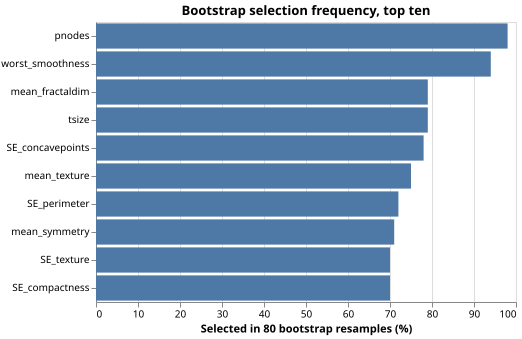

In [4]:
import altair as alt
# Fix the random draw so the resampling result is reproducible.
from collections import Counter

rng = np.random.default_rng(0)
replicates = 80
chosen = Counter()
for _ in range(replicates):
    rows = rng.integers(0, n, n)
    resample = {k: np.asarray(v)[rows] for k, v in modelling.items()}
    refit = mb.glmboost(formula, data=resample, family=mb.Binomial(),
                        control=mb.boost_control(300, 0.1))
    for name in refit.coef():
        if name not in ("(Intercept)", "(offset)"):
            chosen[name] += 1

display(pl.DataFrame([
    {"predictor": name, "selected in": f"{count}/{replicates}",
     "percent": round(100 * count / replicates)}
    for name, count in chosen.most_common(10)
]))

frequency = pl.DataFrame([
    {"predictor": name, "percent": round(100 * count / replicates)}
    for name, count in chosen.most_common(10)
])
alt.Chart(frequency).mark_bar(color="#4e79a7").encode(
    x=alt.X("percent:Q", title="Selected in 80 bootstrap resamples (%)",
            scale=alt.Scale(domain=[0, 100])),
    y=alt.Y("predictor:N", title=None, sort="-x"),
    tooltip=[alt.Tooltip("predictor:N"),
             alt.Tooltip("percent:Q", title="Selected in resamples (%)")],
).properties(title="Bootstrap selection frequency, top ten", width=420, height=280)


The result is a gradient rather than a set. `pnodes` is selected in 78 of 80
replicates and `worst_smoothness` in 75, with the rest declining through the
seventies and sixties to 56 of 80 at the bottom of the top ten. The seventeen
predictors from the single fit therefore differ in how reproducibly they are
chosen, from nearly always to close to half the time.


## Dropping the most frequently selected predictor

The second check tests necessity. Dropping a predictor, refitting, and
comparing cross-validated risk with the full model shows whether the predictor
was required. A predictor that can be removed without changing the risk was
not, regardless of its coefficient or its selection frequency.


In [5]:
folds = mb.cv_weights(n, type="kfold", B=10, seed=2)


def cross_validated(columns):
    model = mb.glmboost("recurred ~ " + " + ".join(columns), data=modelling,
                        family=mb.Binomial(), control=mb.boost_control(300, 0.1))
    return float(np.min(np.asarray(model.cvrisk(folds=folds).aggregate)))


baseline = cross_validated(predictors)
rows = [{"model": f"all {len(predictors)} predictors", "cv risk": round(baseline, 4),
         "vs baseline": "—"}]
for dropped in ("pnodes", "worst_smoothness", "mean_fractaldim"):
    value = cross_validated([c for c in predictors if c != dropped])
    rows.append({"model": f"without {dropped}", "cv risk": round(value, 4),
                 "vs baseline": f"{100 * (value - baseline) / baseline:+.2f}%"})
display(pl.DataFrame(rows))

model,cv risk,vs baseline
str,f64,str
"""all 32 predictors""",0.5361,"""—"""
"""without pnodes""",0.5339,"""-0.41%"""
"""without worst_smoothness""",0.5361,"""+0.00%"""
"""without mean_fractaldim""",0.5361,"""+0.00%"""


Removing `pnodes`, selected in 98% of replicates, changes the cross-validated
risk from 0.5361 to 0.5339, a decrease of about 0.41%. Removing
`worst_smoothness` or `mean_fractaldim` changes it by less than 0.0001.

A predictor can therefore be selected almost every time and still be
unnecessary, when what it contributes is available from other predictors.


## Extension: alternative predictor subsets

The third check compares the cross-validated risk of candidate subsets against
the full set of 32, including subsets the fit did not favour.


predictors used,count,cv risk
str,i64,f64
"""all 32""",32,0.5361
"""pnodes alone""",1,0.5416
"""the two most-selected""",2,0.5429
"""four others entirely""",4,0.5369


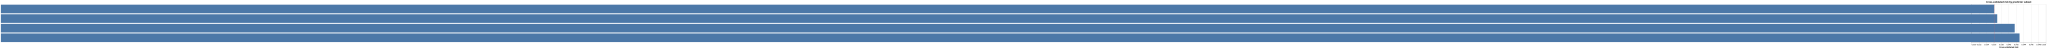

In [6]:
import altair as alt
# Plot the quantities interpreted in the following paragraph.
alternatives = {
    "all 32": predictors,
    "pnodes alone": ["pnodes"],
    "the two most-selected": ["pnodes", "worst_smoothness"],
    "four others entirely": ["tsize", "mean_texture", "SE_perimeter",
                             "mean_symmetry"],
}
subset_frame = pl.DataFrame([
    {"predictors used": label, "count": len(columns),
     "cv risk": round(cross_validated(columns), 4)}
    for label, columns in alternatives.items()
])
display(subset_frame)

rule = alt.Chart(pl.DataFrame({"cv risk": [round(baseline, 4)]})).mark_rule(
    color="#e15759", strokeDash=[4, 3], strokeWidth=1.2
).encode(x="cv risk:Q")
bars = alt.Chart(subset_frame).mark_bar().encode(
    x=alt.X("cv risk:Q", title="Cross-validated risk",
            scale=alt.Scale(domain=[0.53, 0.55])),
    y=alt.Y("predictors used:N", title=None, sort="x"),
    tooltip=[alt.Tooltip("predictors used:N"),
             alt.Tooltip("count:Q", title="Predictors"),
             alt.Tooltip("cv risk:Q", format=".4f", title="cv risk")],
)
alt.layer(bars, rule).properties(
    title="Cross-validated risk by predictor subset",
    width=420, height=220,
)


Four predictors that the single fit did not place near the top — `tsize`,
`mean_texture`, `SE_perimeter` and `mean_symmetry` — reach a cross-validated
risk of 0.5369 against 0.5361 for all thirty-two, a difference of about 0.15%.
`pnodes` alone reaches 0.5416, and the two most-chosen predictors together
0.5429.

The selected seventeen are one subset with predictive information. The
similar cross-validated risks show that other subsets can predict about as
well on these folds; they do not identify a unique set of relevant measurements.


## Extension: `varimp` and selection frequency

`varimp` provides a third view. Instead of counting how often a predictor is
chosen, it attributes the total in-sample risk reduction along the boosting
path to the learner responsible for each step, so a predictor's score is the
share of the improvement that passed through it. It is computed from a single
fit, without resampling.

Comparing it with the bootstrap selection frequency shows whether the two agree
about which predictors matter.


In [7]:
importance = fit.varimp()["reduction"]
ranked = sorted(((k, v) for k, v in importance.items()
                 if k not in ("(Intercept)", "(offset)")),
                key=lambda kv: -kv[1])

by_varimp = {name: rank for rank, (name, _) in enumerate(ranked, start=1)}
by_frequency = {name: rank for rank, (name, _) in
                enumerate(chosen.most_common(), start=1)}

rows = []
for name, share in ranked[:8]:
    rows.append({
        "predictor": name,
        "varimp share": f"{share:.1%}",
        "varimp rank": by_varimp[name],
        "frequency rank": by_frequency.get(name),
        "selected in": f"{chosen[name]}/{replicates}",
    })
display(pl.DataFrame(rows))

top_five = sum(share for _, share in ranked[:5])
print(f"\nthe top five predictors account for {top_five:.0%} of the "
      f"in-sample risk reduction")

predictor,varimp share,varimp rank,frequency rank,selected in
str,str,i64,i64,str
"""worst_area""","""19.2%""",1,13,"""44/80"""
"""pnodes""","""14.0%""",2,1,"""78/80"""
"""worst_smoothness""","""9.6%""",3,2,"""75/80"""
"""worst_radius""","""8.6%""",4,19,"""27/80"""
"""tsize""","""7.4%""",5,4,"""63/80"""
"""mean_fractaldim""","""6.6%""",6,3,"""63/80"""
"""mean_texture""","""6.5%""",7,6,"""60/80"""
"""mean_symmetry""","""5.9%""",8,8,"""57/80"""



the top five predictors account for 59% of the in-sample risk reduction


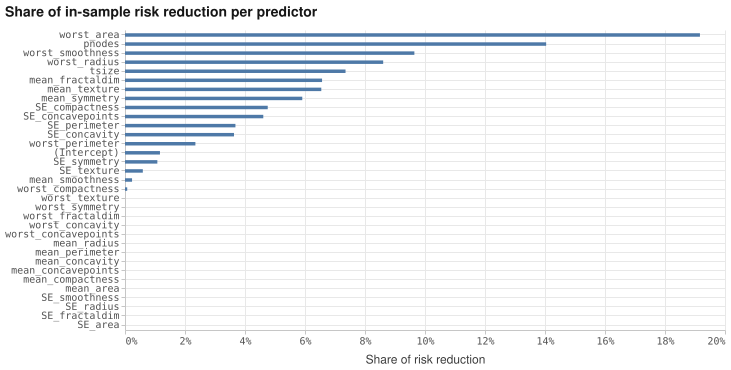

In [8]:
chart = mb.plot.plot_varimp(fit)
chart.properties(title="Share of in-sample risk reduction per predictor")


The two measures disagree. `worst_area` accounts for the largest share of the
risk reduction at 19.2% and ranks 13th by selection frequency, chosen in 44 of
80 resamples. `worst_radius` is fourth by `varimp` and 19th by frequency, at 27
of 80. `pnodes`, chosen in 78 of 80, ranks second by `varimp` and is the
predictor the drop test showed can be removed without cost.

The two measures answer different questions. Selection frequency measures how
reproducibly a predictor is chosen when the data are perturbed. `varimp`
measures how much of one fit's improvement passed through it, and under
correlation that quantity is unstable: a predictor reached first receives
credit that a substitute would otherwise have taken, and `worst_area`,
`worst_radius` and `worst_perimeter` describe one tumour. A predictor can therefore receive a large share of one path's risk reduction
while being selected in only about half the resamples.

The top five predictors account for 59% of the in-sample risk reduction, which
appears to be a concentrated signal. The identity of those five changes across
resamples.


## Extension: stability selection

The bootstrap table separates the reproducibly chosen from the arbitrary
without setting a threshold. Stability selection supplies one: it takes a bound
on the expected number of false positives and retains only terms whose
selection frequency clears the corresponding cutoff, chosen so that across the
q candidate terms the expected number clearing it by chance is at most the
bound. Running it at three bounds shows how the output varies.


In [9]:
rows = []
stabsel_results = {}
for q, pfer in ((6, 1.0), (10, 3.0), (15, 5.0)):
    result = mb.stabsel(fit, q=q, PFER=pfer, B=50)
    stabsel_results[(q, pfer)] = result
    frequency = np.asarray(result.max_)
    ranked = np.argsort(-frequency)[:3]
    rows.append({
        "q": q, "PFER": pfer,
        "cutoff": round(float(result.cutoff), 3),
        "selected": len(result.selected),
        "top frequencies": ", ".join(
            f"{result.learner_names[i]} {frequency[i]:.2f}" for i in ranked),
    })
display(pl.DataFrame(rows))

/tmp/ipykernel_67442/48897486.py:4: UserWarning: mstop too small in some subsampling replicates to select q=15 base-learners; Increase mstop before applying stabsel. 42 of 100 fits fell short (B=50 complementary pairs, 100 fits) and the best reached 15 distinct learners. A model whose path keeps re-selecting the same few terms may not reach q=15 at any mstop, in which case lower q instead: a fold that never reaches q also never stops early, so the run costs the full mstop.
  result = mb.stabsel(fit, q=q, PFER=pfer, B=50)


q,PFER,cutoff,selected,top frequencies
i64,f64,f64,i64,str
6,1.0,0.78,0,"""pnodes 0.71, tsize 0.59, worst…"
10,3.0,0.76,1,"""pnodes 0.82, worst_smoothness …"
15,5.0,0.83,2,"""pnodes 0.91, worst_smoothness …"


At a bound of one expected false positive the procedure returns nothing. The
most-chosen predictor, `pnodes`, is selected in 71% of the 50 subsamples,
against a cutoff of 0.78. At a bound of three it returns `pnodes` alone, at 82%
against a cutoff of 0.76, and at five it returns `pnodes` and
`worst_smoothness`, at 91% and 85% against a cutoff of 0.83.

With 194 patients, 46 events and 32 correlated candidates, no individual
predictor is reliably distinguishable from its substitutes at a strict error
rate.


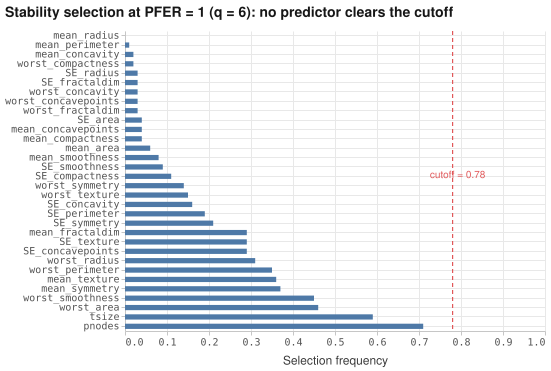

In [10]:
import altair as alt
# Plot the quantities interpreted in the following paragraph.
result = stabsel_results[(6, 1.0)]
names = np.asarray(result.learner_names)
frequency = np.asarray(result.max_)
keep = np.array([name not in ("(Intercept)", "(offset)") for name in names])
order = np.argsort(-frequency[keep])
stable_frame = pl.DataFrame({
    "learner": names[keep][order],
    "frequency": frequency[keep][order],
})
bars = alt.Chart(stable_frame).mark_bar(color="#4e79a7").encode(
    x=alt.X("frequency:Q", title="Selection frequency",
            scale=alt.Scale(domain=[0, 1])),
    y=alt.Y("learner:N", title=None, sort="x"),
    tooltip=[alt.Tooltip("learner:N"),
             alt.Tooltip("frequency:Q", format=".2f", title="Frequency")],
)
rule = alt.Chart(pl.DataFrame({"cutoff": [float(result.cutoff)]})).mark_rule(
    color="#e15759", strokeDash=[4, 3], strokeWidth=1.2
).encode(x="cutoff:Q")
label = alt.Chart(pl.DataFrame({
    "cutoff": [float(result.cutoff)],
    "label": [f"cutoff = {float(result.cutoff):.2f}"],
})).mark_text(color="#e15759", fontSize=10, dx=5, dy=-6).encode(
    x="cutoff:Q", text="label:N")
alt.layer(bars, rule, label).properties(
    title="Stability selection at PFER = 1 (q = 6): no predictor clears the cutoff",
    width=420, height=300,
)


## Conclusions

The measurements carry predictive signal: every model above improves on an
intercept, and `pnodes` and `worst_smoothness` are the most consistently chosen
predictors.

Being chosen most consistently does not make them the biologically important
variables. Removing `pnodes` changes the cross-validated risk by less than its
own resampling variation.

Nor do the seventeen selected predictors amount to seventeen findings. Several
are selected in about half the resamples, and a disjoint set of four predicts
about as well as all thirty-two.

Stability selection returning nothing says something narrower than "no signal":
no individual predictor is distinguishable from its substitutes at that error
rate. Prediction and identification are different tasks, and these data support
the first better than the second.

When predictors are correlated the mapping from signal to selected subset is
one-to-many, and which subset a procedure returns depends on noise, the fold
split and the order of evaluation. Selection frequency separates the
reproducibly chosen from the arbitrary, a removal test separates the necessary
from the redundant, and an explicit error rate gives an empty result a definite
meaning. None of these change what the model predicts; they change what a
single selected subset can be reported to mean.
